In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# --- load & split ---
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# --- pipeline ---
clf = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale")),
])

clf.fit(X_train, y_train)

print(f"Accuracy: {clf.score(X_test, y_test):.4f}")
print(f"Support vectors per class: {clf['svm'].n_support_}")
print(f"Total support vectors: {clf['svm'].n_support_.sum()}")

Accuracy: 0.9667
Support vectors per class: [10 18 19]
Total support vectors: 47


In [3]:
from sklearn.svm import LinearSVC

clf = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(C=1.0, max_iter=10000)),
])

Option A — 2-feature visualization (clearest margins)

Accuracy: 0.9333


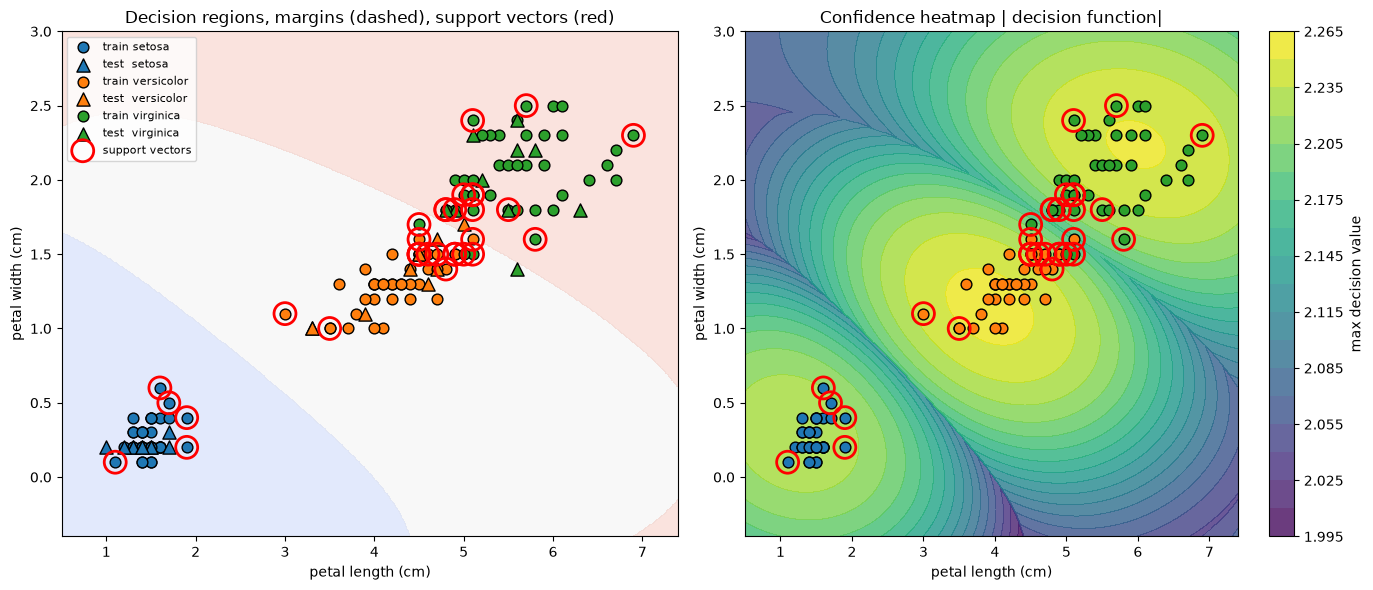

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# --- load iris, keep 2 features: petal length (idx 2), petal width (idx 3) ---
iris = load_iris()
X = iris.data[:, [2, 3]]
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

clf = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale")),
])
clf.fit(X_train, y_train)
print(f"Accuracy: {clf.score(X_test, y_test):.4f}")

# --- build a fine grid over the SCALED feature space ---
scaler = clf["scaler"]
svm = clf["svm"]

x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500),
                     np.linspace(y_min, y_max, 500))
grid = np.c_[xx.ravel(), yy.ravel()]

# decision_function: for 3 classes returns (n, 3) — use max for "confidence"
Z = svm.decision_function(scaler.transform(grid)).reshape(xx.shape[0], xx.shape[1], -1)
Zmax = Z.max(axis=2)                  # per-class score; margins at Zmax == 1

# --- plot ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# left: decision regions + margins
ax = axes[0]
# filled decision regions
Zpred = svm.predict(scaler.transform(grid)).reshape(xx.shape)
ax.contourf(xx, yy, Zpred, alpha=0.2, cmap="coolwarm", levels=[-0.5, 0.5, 1.5, 2.5])
# decision boundary (Zmax == 0) and margins (Zmax == ±1) for the "top" class
ax.contour(xx, yy, Zmax, levels=[-1, 0, 1], colors="k",
           linestyles=["--", "-", "--"], linewidths=[1, 2, 1])

colors = ["tab:blue", "tab:orange", "tab:green"]
for cls in range(3):
    m_tr = y_train == cls
    m_te = y_test == cls
    ax.scatter(X_train[m_tr, 0], X_train[m_tr, 1], c=colors[cls],
               marker="o", edgecolor="k", s=60, label=f"train {iris.target_names[cls]}")
    ax.scatter(X_test[m_te, 0], X_test[m_te, 1], c=colors[cls],
               marker="^", edgecolor="k", s=90, label=f"test  {iris.target_names[cls]}")

# highlight support vectors
sv = X_train[svm.support_]
ax.scatter(sv[:, 0], sv[:, 1], s=250, facecolors="none",
           edgecolors="red", linewidths=2, label="support vectors")

ax.set_xlabel("petal length (cm)")
ax.set_ylabel("petal width (cm)")
ax.set_title("Decision regions, margins (dashed), support vectors (red)")
ax.legend(loc="upper left", fontsize=8)

# right: |decision_function| — distance-to-boundary heatmap
ax = axes[1]
im = ax.contourf(xx, yy, Zmax, levels=20, cmap="viridis", alpha=0.8)
ax.contour(xx, yy, Zmax, levels=[-1, 0, 1], colors="white",
           linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
for cls in range(3):
    m = y_train == cls
    ax.scatter(X_train[m, 0], X_train[m, 1], c=colors[cls],
               marker="o", edgecolor="k", s=60)
ax.scatter(sv[:, 0], sv[:, 1], s=250, facecolors="none",
           edgecolors="red", linewidths=2)
ax.set_xlabel("petal length (cm)")
ax.set_ylabel("petal width (cm)")
ax.set_title("Confidence heatmap | decision function|")
plt.colorbar(im, ax=ax, label="max decision value")
plt.tight_layout()
plt.show()

Option B — all 4 features via PCA (keeps full model)

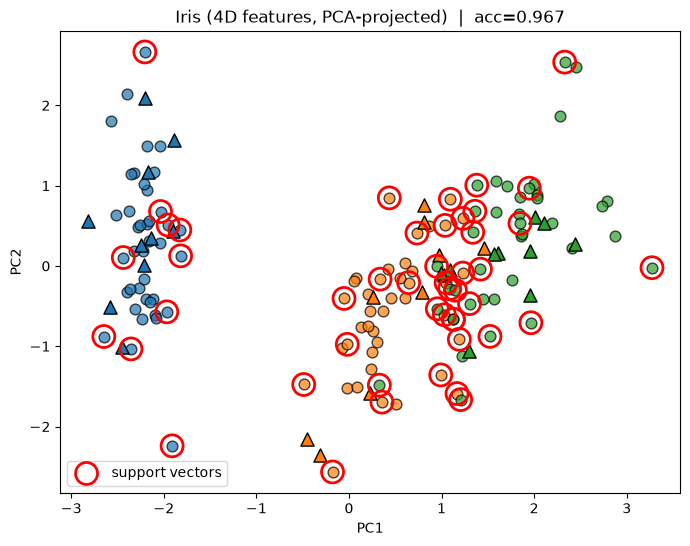

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# train on all 4 features
clf = Pipeline([("scaler", StandardScaler()),
                ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))])
clf.fit(X_train, y_train)

# separate PCA just for plotting (fit on train)
pca = PCA(n_components=2).fit(StandardScaler().fit_transform(X_train))
Xtr2 = pca.transform(StandardScaler().fit_transform(X_train))
Xte2 = pca.transform(StandardScaler().fit_transform(X_test))

# project the SVM's support vectors the same way
scaler = clf["scaler"]
Xtr_scaled = scaler.transform(X_train)
sv_scaled = Xtr_scaled[clf["svm"].support_]
sv2 = pca.transform(sv_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
colors = ["tab:blue", "tab:orange", "tab:green"]
for cls in range(3):
    ax.scatter(Xtr2[y_train == cls, 0], Xtr2[y_train == cls, 1],
               c=colors[cls], marker="o", edgecolor="k", s=60, alpha=0.7)
    ax.scatter(Xte2[y_test == cls, 0], Xte2[y_test == cls, 1],
               c=colors[cls], marker="^", edgecolor="k", s=90)
ax.scatter(sv2[:, 0], sv2[:, 1], s=250, facecolors="none",
           edgecolors="red", linewidths=2, label="support vectors")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"Iris (4D features, PCA-projected)  |  acc={clf.score(X_test,y_test):.3f}")
ax.legend()
plt.show()

Accuracy: 1.0000


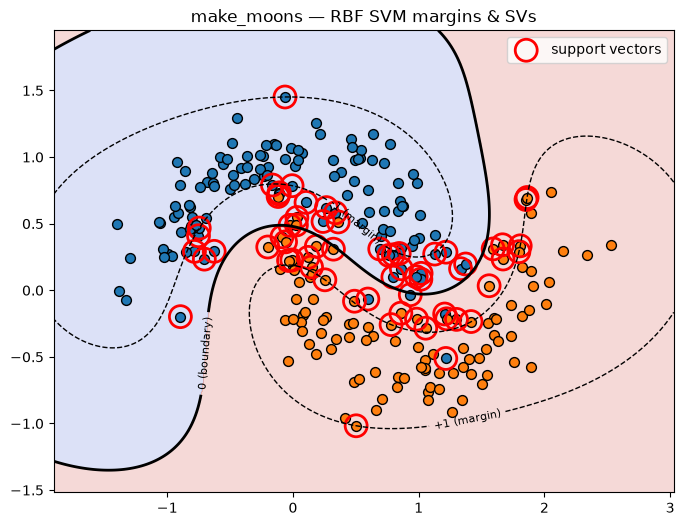

In [7]:
from sklearn.datasets import make_moons
X, y = make_moons(n_samples=300, noise=0.2, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

clf = Pipeline([("scaler", StandardScaler()),
                ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))])
clf.fit(X_train, y_train)
print(f"Accuracy: {clf.score(X_test, y_test):.4f}")

scaler, svm = clf["scaler"], clf["svm"]
xx, yy = np.meshgrid(np.linspace(X[:,0].min()-0.5, X[:,0].max()+0.5, 500),
                     np.linspace(X[:,1].min()-0.5, X[:,1].max()+0.5, 500))
Z = svm.decision_function(scaler.transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)
Zpred = svm.predict(scaler.transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Zpred, alpha=0.2, cmap="coolwarm")
cs = plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k",
                 linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
plt.clabel(cs, fmt={-1: "-1 (margin)", 0: "0 (boundary)", 1: "+1 (margin)"}, fontsize=8)
for cls, c in [(0, "tab:blue"), (1, "tab:orange")]:
    m = y_train == cls
    plt.scatter(X_train[m,0], X_train[m,1], c=c, marker="o", edgecolor="k", s=50)
sv = X_train[svm.support_]
plt.scatter(sv[:,0], sv[:,1], s=250, facecolors="none", edgecolors="red", linewidths=2,
            label="support vectors")
plt.legend(); plt.title("make_moons — RBF SVM margins & SVs")
plt.show()